# 🌎 RemoteCLIP Model Testing

## 📁 Identifying orthomosaic directory structure.

In [1]:
import os

Creating a copy of the data in MyDrive to avoid altering original data.

In [2]:
# perm_dir = '/content/drive/MyDrive/remoteclip_data'
# os.makedirs(perm_dir, exist_ok=True)

Unzipping the data.

In [3]:
!unzip -q "/content/drive/MyDrive/remoteclip_data/VM8.zip" -d /content/data

Creating folders for .rar data

In [4]:
vm8_path= "/content/data/VM8/"
vm8_files = ['terra_dem.rar', 'terra_dom.rar', 'terra_dsm.rar', 'terra_las.rar']
dest = "/content/data/VM8/"

for p in vm8_files:
  path = dest + p.rstrip('.rar')
  os.makedirs(path, exist_ok=True)

Installing unrar and opening the rar files into their respective folders

In [5]:
!apt-get -qq install unrar

In [6]:
for p in vm8_files:
    rar_path = vm8_path + p
    !unrar x -idq "{rar_path}" "{dest}"

The folders that we are going to use:
- DSM
- DEM
- DOM

## 📁 Opening DOM

### 📚 PACKAGES

In [7]:
!pip install -q git+https://github.com/facebookresearch/segment-anything.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [8]:
!wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth -P /content/drive/MyDrive/sam

In [9]:
import geopandas as gpd
import geemap
import pandas as pd
# import rioxarray as rxr
import rasterio
from rasterio.plot import show
from rasterio.windows import Window
from rasterio.windows import bounds as window_bounds
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from scipy import ndimage as ndi
from skimage.morphology import remove_small_objects, remove_small_holes
from matplotlib.colors import ListedColormap
import pysal
from affine import Affine
# import contextily as ctx
import xarray as xr
import folium
import os
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from shapely.geometry import box
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import torch
from scipy import ndimage as ndi
from skimage.morphology import remove_small_objects, remove_small_holes
from skimage.segmentation import find_boundaries
from tqdm.auto import tqdm
from segment_anything import sam_model_registry, SamPredictor, SamAutomaticMaskGenerator
warnings.filterwarnings("ignore")

In [10]:
DOM_PATH = "/content/data/VM8/terra_dom/dom.tif"

In [11]:
with rasterio.open(DOM_PATH) as src:
    print(src.count, src.dtypes)                  # 4 bands, uint8
    print(src.colorinterp)                        # red, green, blue, alpha

    red = src.read(1)                             # single band -> 2D array (rows, cols)
    rgb = src.read([1, 2, 3])                     # several bands -> (3, rows, cols)
    everything = src.read()

4 ('uint8', 'uint8', 'uint8', 'uint8')
(<ColorInterp.red: 3>, <ColorInterp.green: 4>, <ColorInterp.blue: 5>, <ColorInterp.alpha: 6>)


In [12]:
with rasterio.open(DOM_PATH) as src:
  print("CRS:", src.crs)
  print("Band count:", src.count)
  print("Bounds:", src.bounds)
  dom_crs = src.crs

  # Read the first band as a numpy array
  band1 = src.read(1)

CRS: EPSG:32719
Band count: 4
Bounds: BoundingBox(left=263910.9354684872, bottom=6341422.044243328, right=265239.2690684872, top=6342865.336043328)


Visualizing a single tile in the center of VM8.

valid fraction: 0.4338674312700287
data spans rows 2800 - 24960 and cols 1600 - 23480
valid fraction in tile: 1.0


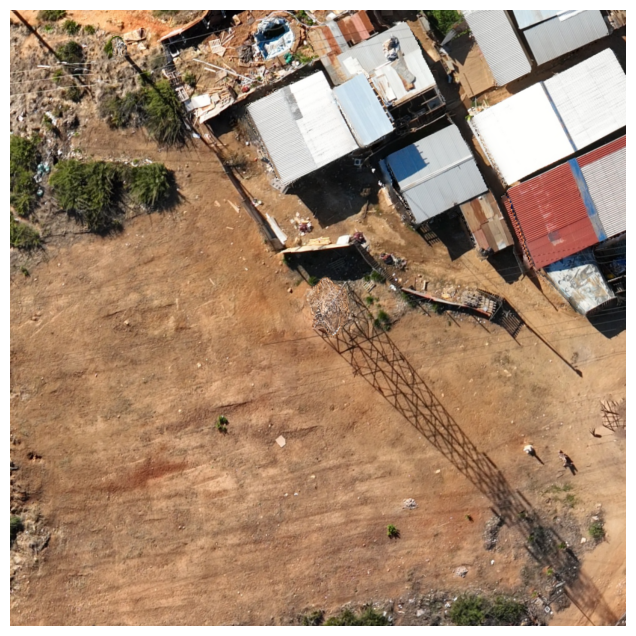

In [13]:
with rasterio.open(DOM_PATH) as src:
    f = 20 # downscaling factor
    alpha = src.read(4, out_shape=(src.height // f, src.width // f),
                     resampling=rasterio.enums.Resampling.nearest)

rows, cols = np.nonzero(alpha)
print("valid fraction:", (alpha > 0).mean())
print("data spans rows", rows.min()*f, "-", rows.max()*f,
      "and cols", cols.min()*f, "-", cols.max()*f)

cy, cx = int(rows.mean() * f), int(cols.mean() * f) # center of img
size = 1024
window = Window(cx - size // 2, cy - size // 2, size, size)
tile_bounds = window_bounds(window, src.transform)   # `window` from your tile code

with rasterio.open(DOM_PATH) as src:
    data = src.read(window=window)

print("valid fraction in tile:", (data[3] > 0).mean())

rgb = data[:3].transpose(1, 2, 0)   # uint8, no scaling needed
plt.figure(figsize=(8, 8))
plt.imshow(rgb)
plt.axis("off")
plt.show()

## Creating Multiple Tiles

Such that there is the least amount of empty space taking up the tile image. The steps are:

In [14]:
DEM_PATH = '/content/data/VM8/terra_dem/dem.tif'
DSM_PATH = '/content/data/VM8/terra_dsm/dsm.tif'

In [15]:
# ---- PARAMETERS ----
f = 4                    # coarse factor (tile must be divisible by f)
TILE = 500              # tile size in full-res px (~55 m)
t = TILE // f            # tile size on the coarse grid
STRIDE = t // 4          # candidate spacing (smaller = better placement, slower)
MIN_ROOF_FRAC = 0.4     # a tile must be at least 40% roof
MIN_GAIN_FRAC = 0.02     # stop when a new tile adds < 2% of a tile of new roof
MIN_VALID = 0.99         # tile must be on valid orthomosaic data
MIN_AREA_M2 = 10         # ignore objects smaller than this

In [16]:
# FUNCTION TO READ MODELS
def read_grid(path, crs, transform, width, height, resampling):
    """Read a raster resampled onto an arbitrary grid. NaN = nodata."""
    with rasterio.open(path) as src:
        nodata = src.nodata if src.nodata is not None else np.nan
        with WarpedVRT(src, crs=crs, transform=transform, width=int(width),
                       height=int(height), resampling=resampling, nodata=nodata) as vrt:
            return vrt.read(1, masked=True).astype("float32").filled(np.nan)

In [17]:
# FUNCTION TO READ ORTHOMOSAIC
with rasterio.open(DOM_PATH) as ortho:
    crs, tf = ortho.crs, ortho.transform
    H, W = ortho.height, ortho.width
    Hc, Wc = H // f, W // f
    tf_c = tf * Affine.scale(f)                       # coarse grid transform
    valid = ortho.read(4, window=Window(0, 0, Wc * f, Hc * f),
                       out_shape=(Hc, Wc), resampling=Resampling.nearest) > 0

dsm_c = read_grid(DSM_PATH, crs, tf_c, Wc, Hc, Resampling.average)
dem_c = read_grid(DEM_PATH, crs, tf_c, Wc, Hc, Resampling.average)
ndsm_c = dsm_c - dem_c

roof = (np.nan_to_num(ndsm_c, nan=0) > 2) & valid
roof = ndi.binary_opening(roof, structure=np.ones((3, 3)))
roof = remove_small_objects(roof, min_size=int(MIN_AREA_M2 / abs(tf_c.a) ** 2))
print("roof fraction of valid area:", roof.sum() / valid.sum())

roof fraction of valid area: 0.23626061560972472


In [18]:
def integral(a):
    S = np.zeros((a.shape[0] + 1, a.shape[1] + 1), dtype=np.int32)
    S[1:, 1:] = a.astype(np.int32).cumsum(0).cumsum(1)
    return S

def box_sums(S, rs, cs, t):
    return (S[np.ix_(rs + t, cs + t)] - S[np.ix_(rs, cs + t)]
            - S[np.ix_(rs + t, cs)] + S[np.ix_(rs, cs)])

# candidate top-left corners on the coarse grid
rs = np.arange(0, Hc - t + 1, STRIDE)
cs = np.arange(0, Wc - t + 1, STRIDE)

valid_frac = box_sums(integral(valid), rs, cs, t) / t**2
roof_frac  = box_sums(integral(roof),  rs, cs, t) / t**2
eligible = (valid_frac >= MIN_VALID) & (roof_frac >= MIN_ROOF_FRAC)
print(eligible.sum(), "eligible candidates")

uncovered = roof.copy()
gain = box_sums(integral(uncovered), rs, cs, t).astype(float)
gain[~eligible] = -1
min_gain = MIN_GAIN_FRAC * t**2
picked = []

while True:
    i, j = np.unravel_index(gain.argmax(), gain.shape)
    if gain[i, j] < min_gain:
        break
    r, c = rs[i], cs[j]
    picked.append((r, c))
    uncovered[r:r + t, c:c + t] = False

    # update gains only for candidates that overlap the new tile
    ri = np.where((rs > r - t) & (rs < r + t))[0]
    ci = np.where((cs > c - t) & (cs < c + t))[0]
    r0, c0 = rs[ri[0]], cs[ci[0]]
    sub = uncovered[r0:rs[ri[-1]] + t, c0:cs[ci[-1]] + t]
    g = box_sums(integral(sub), rs[ri] - r0, cs[ci] - c0, t)
    gain[np.ix_(ri, ci)] = np.where(eligible[np.ix_(ri, ci)], g, -1)

# tile table: pixel windows + map footprints (full-resolution coordinates)
records = []
for k, (r, c) in enumerate(picked):
    w = Window(c * f, r * f, TILE, TILE)
    records.append(dict(tile_id=k, col_off=c * f, row_off=r * f, width=TILE, height=TILE,
                        roof_frac=roof[r:r + t, c:c + t].mean(),
                        geometry=box(*window_bounds(w, tf))))
tiles = gpd.GeoDataFrame(records, crs=crs)

print(len(tiles), "tiles")
print("roof area covered:", 1 - uncovered.sum() / roof.sum())
print("mean roof fraction per tile:", tiles.roof_frac.mean())

4120 eligible candidates
747 tiles
roof area covered: 0.8165472504043857
mean roof fraction per tile: 0.5117715020080321


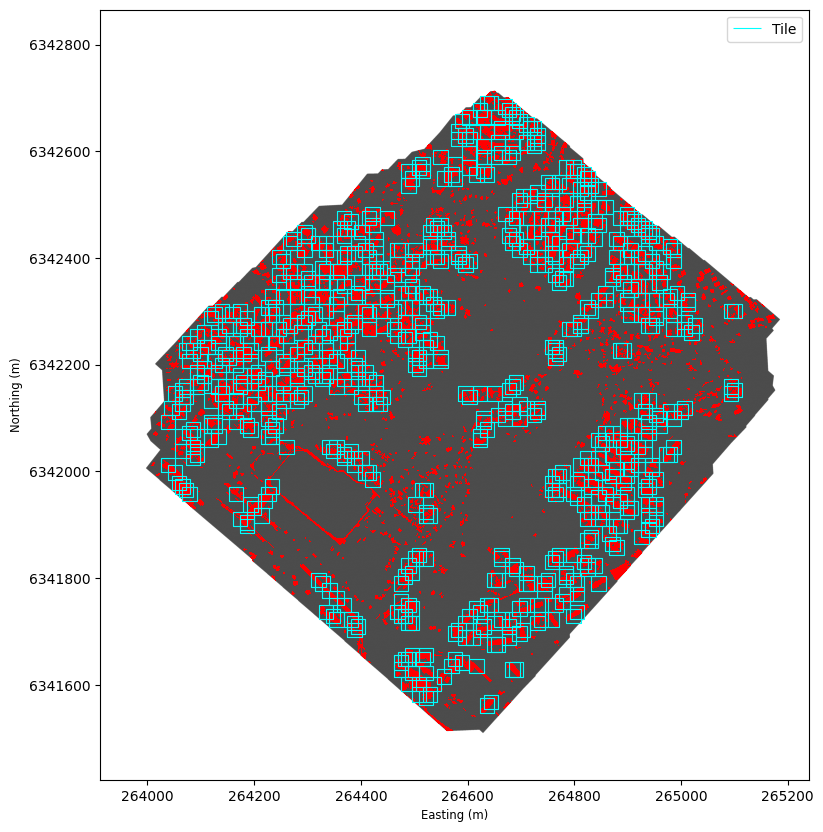

In [19]:
left, bottom, right, top = window_bounds(Window(0, 0, Wc * f, Hc * f), tf)
extent = (left, right, bottom, top)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(np.where(valid, 0.3 + 0.0 * roof, np.nan), cmap="gray", vmin=0, vmax=1, extent=extent)
ax.imshow(np.ma.masked_where(~roof, roof), cmap="autumn", extent=extent, interpolation="nearest", label='Roof')
tiles.boundary.plot(ax=ax, color="cyan", linewidth=0.8, label='Tile')
ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)")
ax.ticklabel_format(useOffset=False, style="plain")
plt.legend()
plt.show()

In [20]:
class RoofTileDataset:
    def __init__(self, tiles, ortho_path, dsm_path, dem_path, thr=2.0):
        self.tiles = tiles.reset_index(drop=True)
        self.ortho_path, self.dsm_path, self.dem_path, self.thr = ortho_path, dsm_path, dem_path, thr

    def __len__(self):
        return len(self.tiles)

    def __getitem__(self, i):
        r = self.tiles.iloc[i]
        w = Window(int(r.col_off), int(r.row_off), int(r.width), int(r.height))
        with rasterio.open(self.ortho_path) as o:
            rgb = o.read([1, 2, 3], window=w)                 # (3, H, W) uint8
            tf_w, crs_w = o.window_transform(w), o.crs
        dsm = read_grid(self.dsm_path, crs_w, tf_w, r.width, r.height, Resampling.bilinear)
        dem = read_grid(self.dem_path, crs_w, tf_w, r.width, r.height, Resampling.bilinear)
        ndsm = dsm - dem
        mask = np.nan_to_num(ndsm, nan=0) > self.thr          # roof label at full res
        return {"image": rgb, "ndsm": ndsm, "mask": mask, "tile_id": int(r.tile_id)}

ds = RoofTileDataset(tiles, DOM_PATH, DSM_PATH, DEM_PATH)
sample = ds[0]

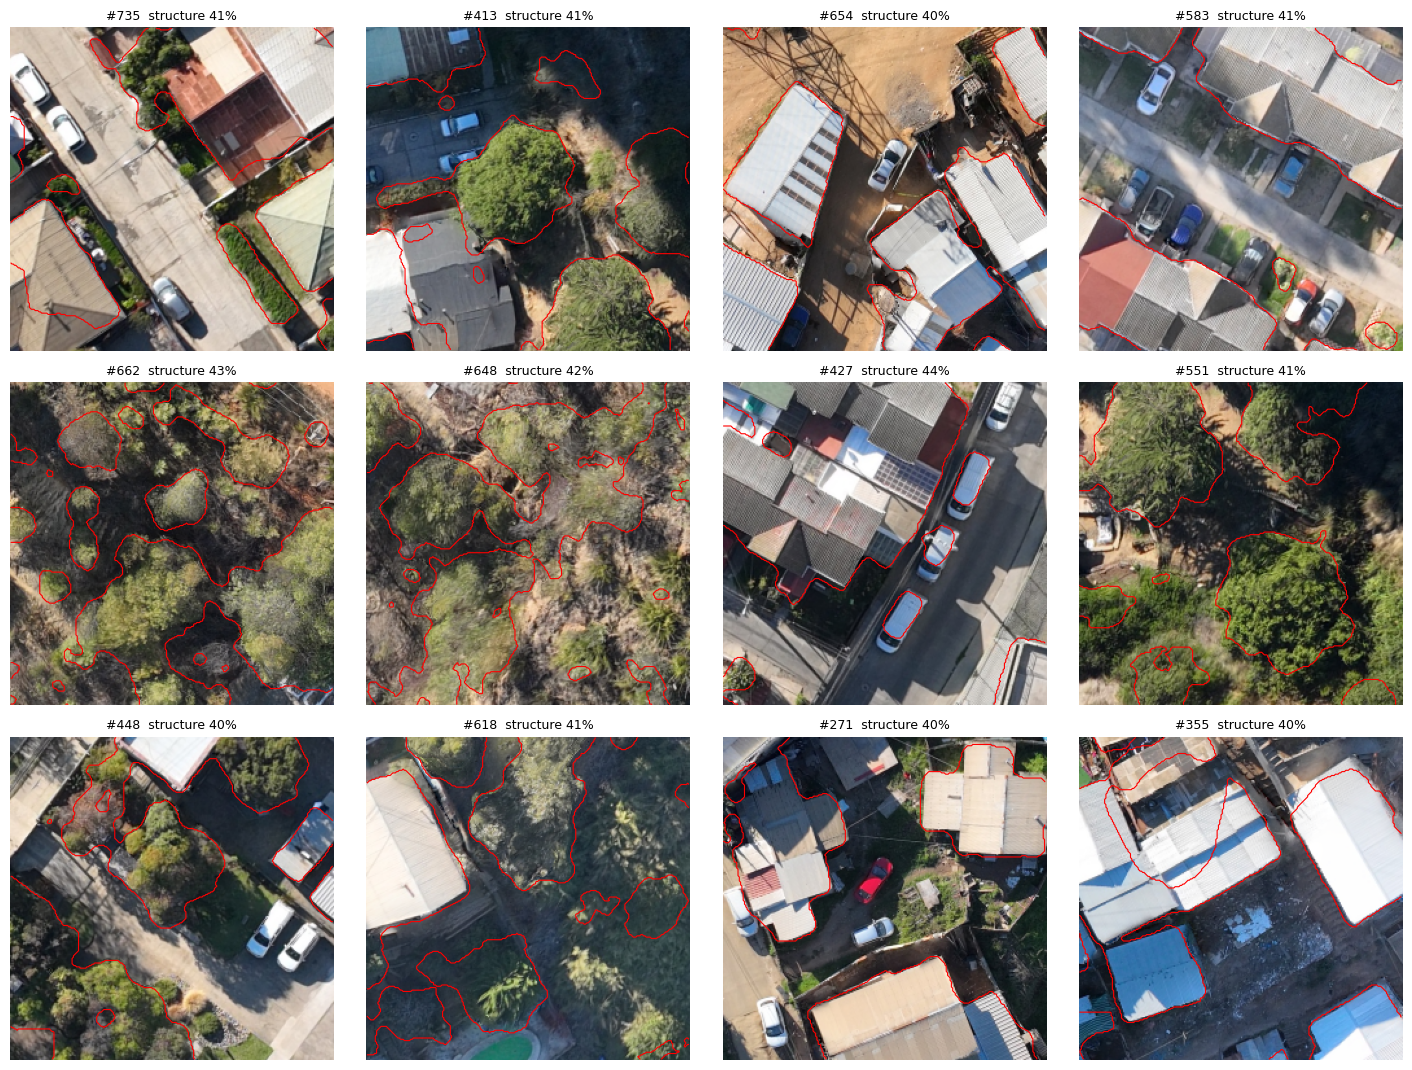

In [21]:
def show_tiles(ids, ncols=4, step=2, size=3.6):
    """ids = positions in `ds`. step = display downsampling (2 -> 512 px)."""
    nrows = int(np.ceil(len(ids) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), ids):
        s = ds[int(i)]
        m = s["mask"][::step, ::step]
        ax.imshow(s["image"][:, ::step, ::step].transpose(1, 2, 0))
        if m.any():
            ax.contour(m, levels=[0.5], colors="red", linewidths=0.8)
        ax.set_title(f"#{i}  structure {m.mean():.0%}", fontsize=9)
    plt.tight_layout(); plt.show()

order = tiles.sort_values("roof_frac").tile_id.values      # weakest tiles first

show_tiles(order[:12])

In [22]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# `ds` positions are the tile ids from here on (ds.tiles has a clean 0..N-1 index)
order_roof = ds.tiles.sort_values("roof_frac").index.values      # weakest first
order_space = np.arange(len(ds))                                  # spatial / generation order

rejected = set()
state = {"order": order_roof, "pos": 0}

btn_first = widgets.Button(description="⏮ First")
btn_prev = widgets.Button(description="◀ Prev")
btn_next = widgets.Button(description="Next ▶")
btn_last = widgets.Button(description="Last ⏭")
btn_reject = widgets.ToggleButton(description="Reject tile", icon="times",
                                  button_style="", layout=widgets.Layout(width="130px"))
btn_order = widgets.ToggleButton(description="Order: weakest first", icon="sort",
                                 layout=widgets.Layout(width="200px"))
label = widgets.HTML()
out = widgets.Output()

def draw():
    n = len(state["order"])
    pos = state["pos"]
    i = int(state["order"][pos])
    s = ds[i]
    left, bottom, right, top = ds.tiles.geometry.iloc[i].bounds
    ext = (left, right, bottom, top)
    rgb = s["image"].transpose(1, 2, 0)

    btn_first.disabled = btn_prev.disabled = pos == 0
    btn_next.disabled = btn_last.disabled = pos == n - 1
    btn_reject.value = i in rejected
    btn_reject.button_style = "danger" if i in rejected else ""
    label.value = (f"<b>Tile {i}</b> &nbsp;|&nbsp; {pos + 1} / {n} &nbsp;|&nbsp; "
                   f"roof {s['mask'].mean():.0%} &nbsp;|&nbsp; {len(rejected)} rejected")

    with out:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharex=True, sharey=True)
        axes[0].imshow(rgb, extent=ext)
        axes[0].set_title("RGB")
        im = axes[1].imshow(s["ndsm"], cmap="viridis", extent=ext, vmin=0, vmax=15)
        axes[1].set_title("nDSM (m)")
        plt.colorbar(im, ax=axes[1], fraction=0.046)
        axes[2].imshow(rgb, extent=ext)
        axes[2].imshow(np.ma.masked_where(~s["mask"], s["mask"]), cmap="autumn",
                       alpha=0.5, extent=ext)
        axes[2].set_title("nDSM > 2 m")
        for ax in axes:
            ax.set_xlabel("Easting (m)")
            ax.ticklabel_format(useOffset=False, style="plain")
            ax.tick_params(axis="x", rotation=45)
        axes[0].set_ylabel("Northing (m)")
        plt.tight_layout()
        plt.show()

def go(pos):
    state["pos"] = max(0, min(len(state["order"]) - 1, pos))
    draw()

def on_reject(change):
    i = int(state["order"][state["pos"]])
    if change["new"]:
        rejected.add(i)
    else:
        rejected.discard(i)
    btn_reject.button_style = "danger" if change["new"] else ""
    label.value = label.value.rsplit("|", 1)[0] + f"| {len(rejected)} rejected"

def on_order(change):
    cur = state["order"][state["pos"]]                       # stay on the same tile
    state["order"] = order_space if change["new"] else order_roof
    state["pos"] = int(np.where(state["order"] == cur)[0][0])
    btn_order.description = "Order: spatial" if change["new"] else "Order: weakest first"
    draw()

btn_first.on_click(lambda b: go(0))
btn_prev.on_click(lambda b: go(state["pos"] - 1))
btn_next.on_click(lambda b: go(state["pos"] + 1))
btn_last.on_click(lambda b: go(len(state["order"]) - 1))
btn_reject.observe(on_reject, names="value")
btn_order.observe(on_order, names="value")

display(widgets.VBox([
    widgets.HBox([btn_first, btn_prev, btn_next, btn_last, btn_reject, btn_order]),
    label,
    out,
]))
draw()

## 🗺️ Crossmatch with AOI and tiles

Testing with center tile of VM8.

In [23]:
aoi_path = '/content/drive/MyDrive/remoteclip_data/incendios.kml'
aoi = gpd.read_file(aoi_path)
aoi = aoi.to_crs(dom_crs)

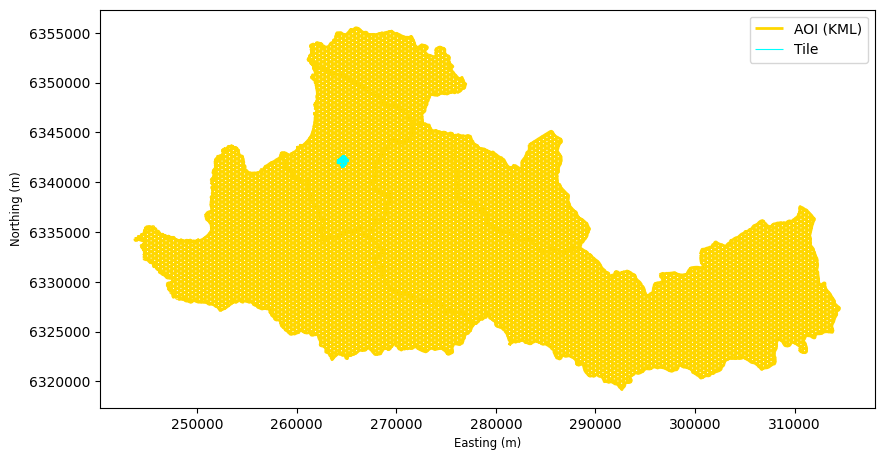

In [24]:
fig, ax = plt.subplots(figsize=(10, 10))
aoi.boundary.plot(ax=ax, color="gold", linewidth=2, label="AOI (KML)")
ax.imshow(np.where(valid, 0.3 + 0.0 * roof, np.nan), cmap="gray", vmin=0, vmax=1, extent=extent)
ax.imshow(np.ma.masked_where(~roof, roof), cmap="autumn", extent=extent, interpolation="nearest", label='Roof')
tiles.boundary.plot(ax=ax, color="cyan", linewidth=0.8, label='Tile')
ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)")
ax.ticklabel_format(useOffset=False, style="plain")
plt.legend()
plt.show()

## ✂️ Segmenting to identify structures

### Without ML (with RGB)

In [25]:
VEG_NGRDI = 0.1                     # ASSUMED: vegetation if NGRDI >= this
NODATA = 255
NAMES = {0: "unclassified", 1: "vegetation", 2: "clear zinc", 3: "rusty zinc", 4: "asphalt"}
COLORS = {0: "#d81b9a", 1: "#2e8b3a", 2: "#cfdbe6", 3: "#c0622d", 4: "#333333"}

In [26]:
def read_rgba(row):
    w = Window(int(row.col_off), int(row.row_off), int(row.width), int(row.height))
    with rasterio.open(DOM_PATH) as o:
        d = o.read(window=w)                          # (4, H, W) uint8
    return d[:3], d[3] > 0                            # rgb, valid mask

def classify(rgb, valid, veg_ngrdi=VEG_NGRDI):
    R, G, B = rgb.astype("float32")                   # float: uint8 sums would overflow
    brillo = (R + G + B) / 3
    den = G + R
    ngrdi = np.divide(G - R, den, out=np.zeros_like(den), where=den > 0)

    veg     = ngrdi >= veg_ngrdi
    clear   = (brillo > 180) & (ngrdi < 0.05)
    rusty   = (brillo >= 100) & (brillo <= 180) & (R > B) & (ngrdi < 0.05)
    asphalt = brillo < 100

    out = np.zeros(R.shape, np.uint8)                 # 0 = unclassified
    out[asphalt] = 4
    out[rusty] = 3
    out[clear] = 2
    out[veg] = 1                                      # written last: vegetation wins any overlap
    out[~valid] = NODATA                              # outside the orthomosaic footprint
    return out

def tile_classes(i):
    return classify(*read_rgba(T.iloc[i]))

In [27]:
T = tiles

In [28]:
def class_fractions(row):
    rgb, valid = read_rgba(row)
    c = classify(rgb, valid)[valid]                   # valid pixels only
    return {f"frac_{name.replace(' ', '_')}": (c == k).mean() for k, name in NAMES.items()}

stats = pd.DataFrame([class_fractions(r) for r in T.itertuples()], index=T.index)
T = T.drop(columns=stats.columns, errors="ignore").join(stats)
print(stats.describe().round(3))

       frac_unclassified  frac_vegetation  frac_clear_zinc  frac_rusty_zinc  \
count            747.000          747.000          747.000          747.000   
mean               0.052            0.268            0.184            0.201   
std                0.046            0.233            0.135            0.118   
min                0.000            0.001            0.000            0.000   
25%                0.020            0.100            0.069            0.119   
50%                0.041            0.187            0.180            0.201   
75%                0.070            0.357            0.273            0.270   
max                0.313            0.991            0.754            0.706   

       frac_asphalt  
count       747.000  
mean          0.294  
std           0.134  
min           0.008  
25%           0.209  
50%           0.282  
75%           0.362  
max           0.829  


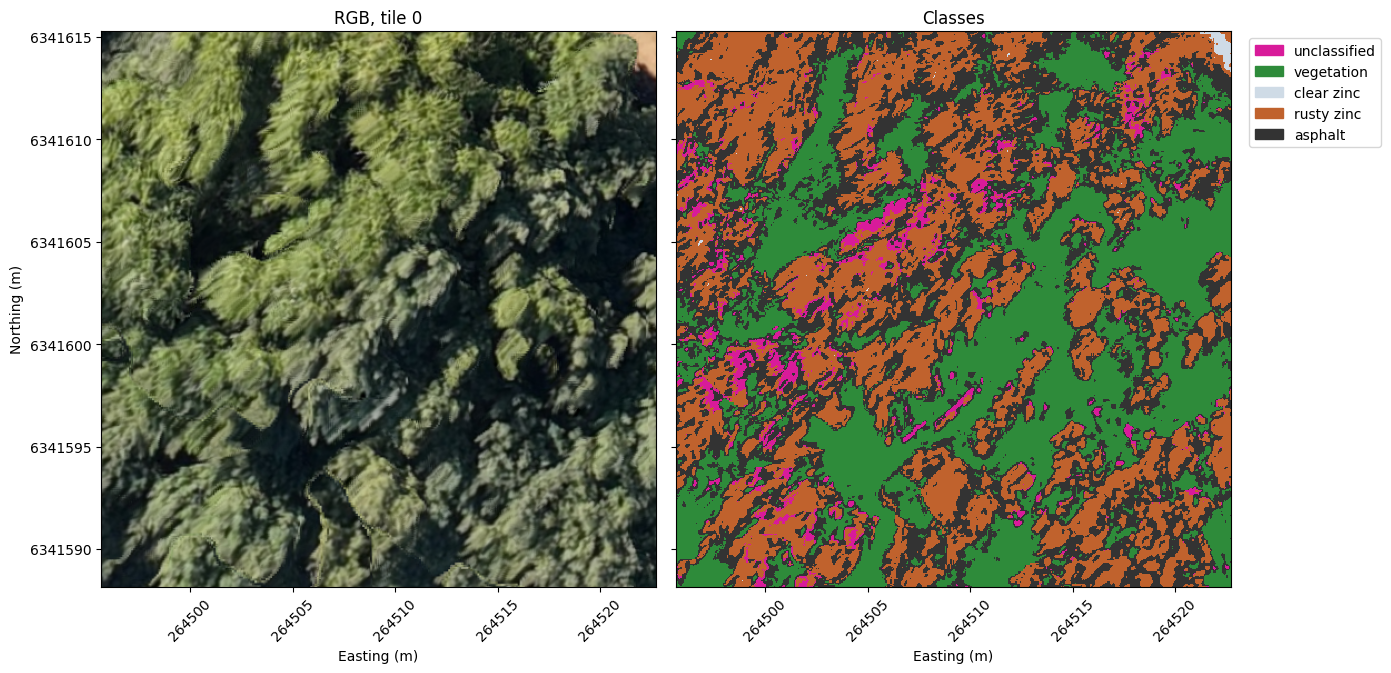

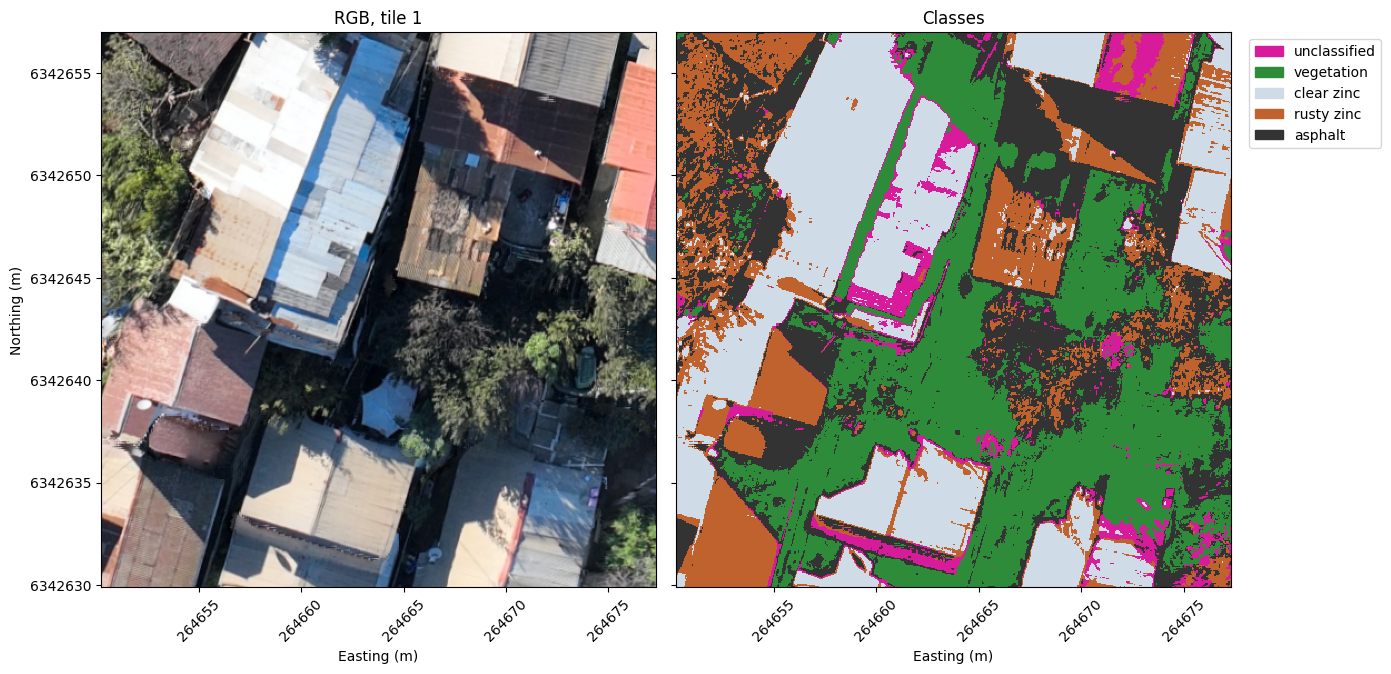

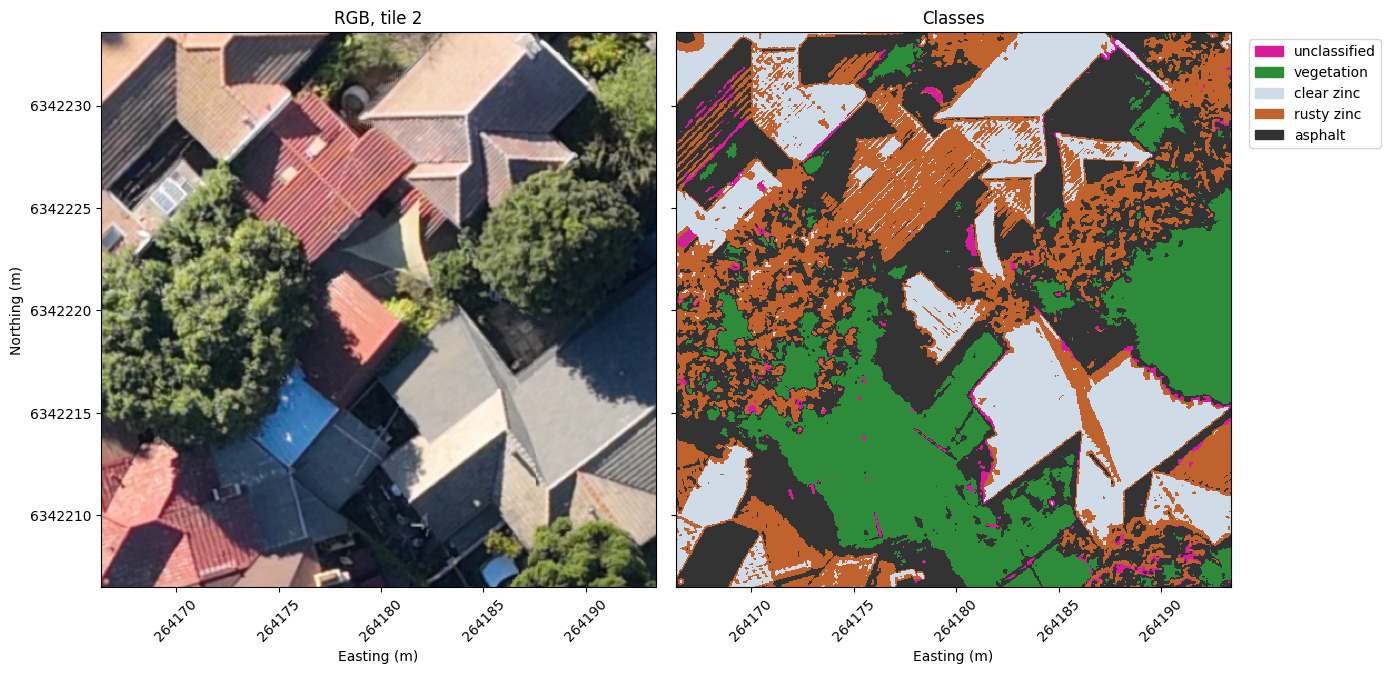

In [29]:
cmap = ListedColormap([COLORS[k] for k in range(5)])
legend = [Patch(color=COLORS[k], label=NAMES[k]) for k in range(5)]

def draw_classes(ax_rgb, ax_cls, i, roof_only=False):
    rgb, valid = read_rgba(T.iloc[i])
    cls = classify(rgb, valid)
    if roof_only:                                     # keep only pixels with nDSM > 2 m
        mask = RoofTileDataset(T, DOM_PATH, DSM_PATH, DEM_PATH)[i]["mask"]
        cls = np.where(mask, cls, NODATA)
    left, bottom, right, top = T.geometry.iloc[i].bounds
    ext = (left, right, bottom, top)

    ax_rgb.imshow(rgb.transpose(1, 2, 0), extent=ext)
    ax_rgb.set_title(f"RGB, tile {i}")
    ax_cls.imshow(np.ma.masked_equal(cls, NODATA), cmap=cmap, vmin=0, vmax=4,
                  extent=ext, interpolation="nearest")
    ax_cls.set_title("Classes")
    for ax in (ax_rgb, ax_cls):
        ax.set_xlabel("Easting (m)")
        ax.ticklabel_format(useOffset=False, style="plain")
        ax.tick_params(axis="x", rotation=45)
    ax_rgb.set_ylabel("Northing (m)")

def show_classes(ids, roof_only=False):
    for i in ids:
        fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)
        draw_classes(axes[0], axes[1], int(i), roof_only)
        axes[1].legend(handles=legend, loc="upper left", bbox_to_anchor=(1.02, 1))
        plt.tight_layout()
        plt.show()

show_classes([0, 1, 2])                               # a few tiles

### With ML (SAM)

In [38]:
import torch
print("GPU:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

from segment_anything import sam_model_registry, SamPredictor

sam = sam_model_registry["vit_b"](checkpoint="/content/drive/MyDrive/sam/sam_vit_b_01ec64.pth").to("cuda")
device = "cuda" if torch.cuda.is_available() else "cpu"
predictor = SamPredictor(sam)
print("SAM loaded")

GPU: True Tesla T4
SAM loaded


In [39]:
with rasterio.open(DOM_PATH) as o:
    pix = o.res[0]                                   # m/px (~0.054)
min_px = int(10 / pix**2)                            # 10 m² in pixels

def clean_roof(mask):
    mask = ndi.binary_opening(mask, structure=np.ones((5, 5)))
    mask = remove_small_objects(mask, min_size=min_px)
    return remove_small_holes(mask, area_threshold=min_px)

def build_instances(masks, infos):
    """Paint masks into one label image, big ones first so small ones stay on top."""
    order = np.argsort([-m.sum() for m in masks])
    inst = np.zeros(masks[0].shape if masks else (1, 1), np.uint16)
    out = []
    for new_id, k in enumerate(order, start=1):
        inst[masks[k]] = new_id
        out.append(dict(id=new_id, area_m2=masks[k].sum() * pix**2, **infos[k]))
    return inst, out

In [40]:
def segment_tile_prompted(i, pad=8, min_iou=0.5, chunk=32):
    s = ds[i]
    rgb = np.ascontiguousarray(s["image"].transpose(1, 2, 0))      # (H, W, 3) uint8
    H, W = rgb.shape[:2]
    roof = clean_roof(s["mask"])
    comp, n = ndi.label(roof, structure=np.ones((3, 3)))
    if n == 0:
        return np.zeros((H, W), np.uint16), []

    boxes = []
    for sl in ndi.find_objects(comp):                               # one box per nDSM object
        y0, y1, x0, x1 = sl[0].start, sl[0].stop, sl[1].start, sl[1].stop
        boxes.append([max(x0 - pad, 0), max(y0 - pad, 0), min(x1 + pad, W), min(y1 + pad, H)])
    boxes = torch.tensor(boxes, dtype=torch.float32, device=device)

    predictor.set_image(rgb)                                        # image embedding, once per tile
    boxes_t = predictor.transform.apply_boxes_torch(boxes, (H, W))

    masks, infos = [], []
    for a in range(0, len(boxes_t), chunk):
        m, sc, _ = predictor.predict_torch(point_coords=None, point_labels=None,
                                           boxes=boxes_t[a:a + chunk], multimask_output=False)
        m, sc = m[:, 0].cpu().numpy(), sc[:, 0].cpu().numpy()
        for j in range(len(m)):
            k = a + j
            c = comp == (k + 1)
            iou = (m[j] & c).sum() / max((m[j] | c).sum(), 1)
            if iou >= min_iou:                                      # SAM mask agrees with the nDSM object
                masks.append(m[j]); infos.append(dict(source="sam", score=float(sc[j]), iou_ndsm=float(iou)))
            else:                                                   # SAM drifted: keep the nDSM object
                masks.append(c);    infos.append(dict(source="ndsm", score=float(sc[j]), iou_ndsm=float(iou)))
    return build_instances(masks, infos)

result = segment_tile_prompted(0)
print(len(result[1]), "structures")

1 structures


# Creating dataset for automatic labeling.

# Loading RemoteCLIP

Creating environment with OpenCLIP. Following instructions at https://github.com/ChenDelong1999/RemoteCLIP/tree/main

In [41]:
# https://pypi.org/project/open-clip-torch/
!pip install open-clip-torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 64.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [open-clip-torch]


In [42]:
from huggingface_hub import hf_hub_download

for model_name in ['RN50', 'ViT-B-32', 'ViT-L-14']:
    checkpoint_path = hf_hub_download("chendelong/RemoteCLIP", f"RemoteCLIP-{model_name}.pt", cache_dir='checkpoints')
    print(f'{model_name} is downloaded to {checkpoint_path}.')

RemoteCLIP-RN50.pt: reconstructing file:   0%|          |  0.00B /  408MB            

RemoteCLIP-RN50.pt: downloading bytes:           |  0.00B            

RN50 is downloaded to /content/checkpoints/models--chendelong--RemoteCLIP/snapshots/bf1d8a3ccf2ddbf7c875705e46373bfe542bce38/RemoteCLIP-RN50.pt.


RemoteCLIP-ViT-B-32.pt: reconstructing file:   0%|          |  0.00B /  605MB            

RemoteCLIP-ViT-B-32.pt: downloading bytes:           |  0.00B            

ViT-B-32 is downloaded to /content/checkpoints/models--chendelong--RemoteCLIP/snapshots/bf1d8a3ccf2ddbf7c875705e46373bfe542bce38/RemoteCLIP-ViT-B-32.pt.


RemoteCLIP-ViT-L-14.pt: reconstructing file:   0%|          |  0.00B / 1.71GB            

RemoteCLIP-ViT-L-14.pt: downloading bytes:           |  0.00B            

ViT-L-14 is downloaded to /content/checkpoints/models--chendelong--RemoteCLIP/snapshots/bf1d8a3ccf2ddbf7c875705e46373bfe542bce38/RemoteCLIP-ViT-L-14.pt.


In [ ]:
import torch, open_clip
from PIL import Image

model_name = 'ViT-L-14' # 'RN50' or 'ViT-B-32' or 'ViT-L-14'
model, _, preprocess = open_clip.create_model_and_transforms(model_name)
tokenizer = open_clip.get_tokenizer(model_name)

ckpt = torch.load(f"path/to/your/checkpoints/RemoteCLIP-{model_name}.pt", map_location="cpu")
message = model.load_state_dict(ckpt)
print(message)

model = model.cuda().eval()